# Predicting Student Academic Performance Using Machine Learning
### UC Berkeley Professional Certificate in AI & Machine Learning Capstone

**Author:** Sunit Poddar  
**Deliverable:** Final technical analysis, model evaluation, and business-oriented findings

---

## Executive summary

This project investigates how demographic, behavioral, family, and school-related information is associated with final mathematics grades. It builds regression baselines, applies cross-validation and hyperparameter search, compares a model that excludes prior grades with one that includes them, and turns measured findings into cautious recommendations for educators.

**Important:** This notebook does not assume the result in advance. Numeric results and interpretations below are generated by the code from the downloaded dataset.

## 1. Business problem and research question

Schools often identify academic struggles only after grades have already fallen. The practical question is whether information available earlier in the year can help staff identify students who may benefit from additional support.

**Research question:** Which demographic, behavioral, and academic factors are the strongest predictors of students' final mathematics grades, and how accurately can regression models predict those grades with and without prior-period grades?

### Objectives

1. Describe data quality and patterns in final mathematics grades.
2. Explore how study time, absences, prior grades, failures, and selected contextual factors relate to final grades.
3. Compare a mean baseline, Multiple Linear Regression, Ridge Regression, Lasso Regression, and K-Nearest Neighbors regression.
4. Evaluate results using a held-out test set and five-fold cross-validation, with hyperparameter search for applicable models.
5. Translate model findings into practical, non-punitive recommendations and document limitations.

### Prediction settings

- **Earlier-support scenario:** excludes `G1` and `G2`. These are prior-period grades, and excluding them tests what can be predicted without them.
- **Later-in-year scenario:** includes `G1` and `G2`. This gives the model more recent academic evidence, but is less useful for early-semester identification.

These are two distinct use cases; do not interpret the later-in-year score as the performance of an early-warning model.

## 2. Data source and context

The data comes from the [UCI Machine Learning Repository — Student Performance](https://archive.ics.uci.edu/dataset/320/student+performance), DOI [10.24432/C5TG7T](https://doi.org/10.24432/C5TG7T). This notebook uses the mathematics-course file, `student-mat.csv`, from the UCI data archive. The data describes secondary-school students at two schools in Portugal.

The outcome `G3` is the final grade on a 0–20 scale. `G1` and `G2` are earlier-period grades. The UCI documentation notes that `G1` and `G2` are strongly correlated with `G3`; therefore, the scenario comparison is important. This is historical data and is not guaranteed to represent current students or other school systems.

The mathematics file is included in this repository at `data/student-mat.csv`, so the analysis can be reproduced without downloading it again. The notebook reads that committed file. If the file is missing, the notebook downloads the official UCI archive and extracts `student-mat.csv`. Please retain attribution to Cortez and the UCI Machine Learning Repository (CC BY 4.0) when reusing the data.

In [1]:
# Core data analysis and visualization libraries
from pathlib import Path
import io
import shutil
import urllib.request
import zipfile
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display, Markdown

# Modeling, validation and evaluation
from sklearn.compose import ColumnTransformer
from sklearn.dummy import DummyRegressor
from sklearn.impute import SimpleImputer
from sklearn.inspection import permutation_importance
from sklearn.linear_model import LinearRegression, Ridge, Lasso
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.model_selection import GridSearchCV, KFold, cross_validate, train_test_split
from sklearn.neighbors import KNeighborsRegressor
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler

pd.set_option("display.max_columns", 50)
pd.set_option("display.width", 140)
sns.set_theme(style="whitegrid", context="notebook")
RANDOM_STATE = 42
TEST_SIZE = 0.20
N_SPLITS = 5
UCI_ARCHIVE_URL = "https://archive.ics.uci.edu/static/public/320/student+performance.zip"

Matplotlib is building the font cache; this may take a moment.


In [2]:
# Find the project root whether Jupyter is launched from the repository root or notebooks/.
def find_project_root() -> Path:
    current = Path.cwd().resolve()
    for candidate in [current, *current.parents]:
        if (candidate / "README.md").exists() and (candidate / "notebooks").exists():
            return candidate
    return current

PROJECT_ROOT = find_project_root()
DATA_DIR = PROJECT_ROOT / "data"
IMAGES_DIR = PROJECT_ROOT / "images"
REPORTS_DIR = PROJECT_ROOT / "reports"
for folder in [DATA_DIR, IMAGES_DIR, REPORTS_DIR]:
    folder.mkdir(parents=True, exist_ok=True)

print(f"Project root: {PROJECT_ROOT}")
print(f"Dataset folder: {DATA_DIR}")

Project root: /Users/sunitpoddar/Downloads/Student-Performance-Prediction-Capstone
Dataset folder: /Users/sunitpoddar/Downloads/Student-Performance-Prediction-Capstone/data


In [3]:
def extract_student_mat(zip_path: Path, csv_path: Path) -> None:
    """Copy student-mat.csv out of the UCI archive.

    The current official download is a zip whose only data member is student.zip.
    The mathematics CSV is inside that inner archive. Older mirrors place the CSV
    at the top level, so both layouts are accepted.
    """
    with zipfile.ZipFile(zip_path) as archive:
        names = archive.namelist()
        direct = next((name for name in names if Path(name).name == "student-mat.csv"), None)
        if direct is not None:
            with archive.open(direct) as source, csv_path.open("wb") as destination:
                shutil.copyfileobj(source, destination)
            return
        nested_name = next((name for name in names if Path(name).name == "student.zip"), None)
        if nested_name is None:
            raise FileNotFoundError(
                f"student-mat.csv was not found in {zip_path.name}. Archive members: {names}"
            )
        nested_bytes = io.BytesIO(archive.read(nested_name))
    with zipfile.ZipFile(nested_bytes) as nested:
        member = next(name for name in nested.namelist() if Path(name).name == "student-mat.csv")
        with nested.open(member) as source, csv_path.open("wb") as destination:
            shutil.copyfileobj(source, destination)


def load_math_dataset() -> pd.DataFrame:
    """Load the official UCI mathematics file, downloading it if needed."""
    csv_path = DATA_DIR / "student-mat.csv"
    if not csv_path.exists():
        zip_path = DATA_DIR / "student-performance.zip"
        try:
            print("Local student-mat.csv not found; downloading the official UCI archive...")
            urllib.request.urlretrieve(UCI_ARCHIVE_URL, zip_path)
            extract_student_mat(zip_path, csv_path)
        except Exception as exc:
            raise RuntimeError(
                "Dataset download failed. Download student-mat.csv from "
                "https://archive.ics.uci.edu/dataset/320/student+performance and save it to data/student-mat.csv."
            ) from exc
    # The source CSV uses semicolons as field separators.
    return pd.read_csv(csv_path, sep=";")

raw_df = load_math_dataset()
display(raw_df.head())
print(f"Loaded {raw_df.shape[0]:,} rows and {raw_df.shape[1]:,} columns.")

,school,sex,age,address,famsize,Pstatus,Medu,Fedu,Mjob,Fjob,reason,guardian,traveltime,studytime,failures,schoolsup,famsup,paid,activities,nursery,higher,internet,romantic,famrel,freetime,goout,Dalc,Walc,health,absences,G1,G2,G3
0,GP,F,18,U,GT3,A,4,4,at_home,teacher,course,mother,2,2,0,yes,no,no,no,yes,yes,no,no,4,3,4,1,1,3,6,5,6,6
1,GP,F,17,U,GT3,T,1,1,at_home,other,course,father,1,2,0,no,yes,no,no,no,yes,yes,no,5,3,3,1,1,3,4,5,5,6
2,GP,F,15,U,LE3,T,1,1,at_home,other,other,mother,1,2,3,yes,no,yes,no,yes,yes,yes,no,4,3,2,2,3,3,10,7,8,10
3,GP,F,15,U,GT3,T,4,2,health,services,home,mother,1,3,0,no,yes,yes,yes,yes,yes,yes,yes,3,2,2,1,1,5,2,15,14,15
4,GP,F,16,U,GT3,T,3,3,other,other,home,father,1,2,0,no,yes,yes,no,yes,yes,no,no,4,3,2,1,2,5,4,6,10,10


Loaded 395 rows and 33 columns.


## 3. Understand the dataset

Each row represents one student record for the mathematics course. The target is `G3`, and the predictors include school, demographics, study time, absences, past failures, family context, and (for the later-in-year scenario only) `G1`/`G2`. The numeric coding for some columns is ordinal—for example, study-time category 1 is lower than category 4—rather than a precise count of hours.

In [4]:
# Summary of column types and dataset dimensions
profile = pd.DataFrame({
    "dtype": raw_df.dtypes.astype(str),
    "non_null": raw_df.notna().sum(),
    "missing": raw_df.isna().sum(),
    "unique_values": raw_df.nunique(dropna=True),
}).sort_values(["dtype", "unique_values"])
print("Dataset shape:", raw_df.shape)
display(profile)

Dataset shape: (395, 33)


,dtype,non_null,missing,unique_values
traveltime,int64,395,0,4
studytime,int64,395,0,4
failures,int64,395,0,4
Medu,int64,395,0,5
Fedu,int64,395,0,5
famrel,int64,395,0,5
freetime,int64,395,0,5
goout,int64,395,0,5
Dalc,int64,395,0,5
Walc,int64,395,0,5


In [5]:
# Quick statistical overview. Categorical text fields are included in the second table.
print("Numeric summary")
display(raw_df.describe().T.round(2))
print("Categorical summary")
display(raw_df.describe(include="object").T)

Numeric summary


,count,mean,std,min,25%,50%,75%,max
age,395.0,16.70,1.28,15.0,16.0,17.0,18.0,22.0
Medu,395.0,2.75,1.09,0.0,2.0,3.0,4.0,4.0
Fedu,395.0,2.52,1.09,0.0,2.0,2.0,3.0,4.0
traveltime,395.0,1.45,0.70,1.0,1.0,1.0,2.0,4.0
studytime,395.0,2.04,0.84,1.0,1.0,2.0,2.0,4.0
failures,395.0,0.33,0.74,0.0,0.0,0.0,0.0,3.0
famrel,395.0,3.94,0.90,1.0,4.0,4.0,5.0,5.0
freetime,395.0,3.24,1.00,1.0,3.0,3.0,4.0,5.0
goout,395.0,3.11,1.11,1.0,2.0,3.0,4.0,5.0
Dalc,395.0,1.48,0.89,1.0,1.0,1.0,2.0,5.0


Categorical summary


,count,unique,top,freq
school,395,2,GP,349
sex,395,2,F,208
address,395,2,U,307
famsize,395,2,GT3,281
Pstatus,395,2,T,354
Mjob,395,5,other,141
Fjob,395,5,other,217
reason,395,4,course,145
guardian,395,3,mother,273
schoolsup,395,2,no,344


## 4. Data-quality checks and cleaning

The checks below report missing values, exact duplicate rows, and data types. Exact duplicate rows are removed. Rows missing the target `G3` cannot be used for supervised regression and are removed. If predictor values are missing, numeric median imputation and categorical most-frequent imputation are fitted **inside each training fold** by the modeling pipeline; this avoids learning imputation values from validation/test records.

In [6]:
quality_before = pd.DataFrame({
    "missing_count": raw_df.isna().sum(),
    "missing_percent": (raw_df.isna().mean() * 100).round(2),
    "dtype": raw_df.dtypes.astype(str),
})
print("Exact duplicate rows before cleaning:", int(raw_df.duplicated().sum()))
display(quality_before.sort_values("missing_count", ascending=False).head(15))

Exact duplicate rows before cleaning: 0


,missing_count,missing_percent,dtype
school,0,0.0,object
paid,0,0.0,object
G2,0,0.0,int64
G1,0,0.0,int64
absences,0,0.0,int64
health,0,0.0,int64
Walc,0,0.0,int64
Dalc,0,0.0,int64
goout,0,0.0,int64
freetime,0,0.0,int64


In [7]:
df = raw_df.copy()
rows_before = len(df)
df = df.drop_duplicates()
duplicates_removed = rows_before - len(df)
if "G3" not in df.columns:
    raise ValueError("Expected target column 'G3' not found. Check the selected dataset file.")
# A numeric target is required for regression.
df["G3"] = pd.to_numeric(df["G3"], errors="coerce")
rows_before_target_cleanup = len(df)
df = df.dropna(subset=["G3"]).copy()
missing_targets_removed = rows_before_target_cleanup - len(df)

print(f"Duplicate rows removed: {duplicates_removed}")
print(f"Rows removed because G3 was missing or non-numeric: {missing_targets_removed}")
print("Rows after cleaning:", len(df))
print("Remaining missing values in predictors:", int(df.drop(columns=["G3"]).isna().sum().sum()))

Duplicate rows removed: 0
Rows removed because G3 was missing or non-numeric: 0
Rows after cleaning: 395
Remaining missing values in predictors: 0


## 5. Target distribution: final mathematics grade

The grade distribution helps assess the target range, concentration, and any unusual values before modeling. Predictions are evaluated in grade points on the same 0–20 scale.

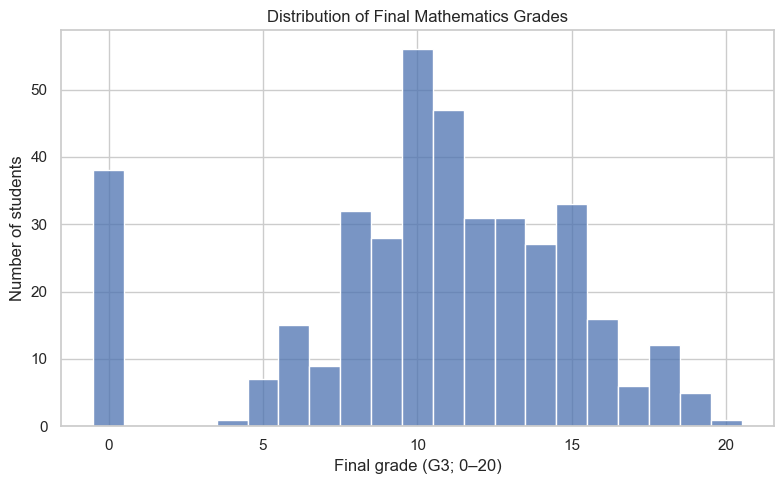

,Final grade (G3)
count,395.00
mean,10.42
std,4.58
min,0.00
25%,8.00
50%,11.00
75%,14.00
max,20.00


In [8]:
fig, ax = plt.subplots(figsize=(8, 5))
sns.histplot(data=df, x="G3", bins=np.arange(-0.5, 21.5, 1), color=sns.color_palette("deep")[0], ax=ax)
ax.set(title="Distribution of Final Mathematics Grades", xlabel="Final grade (G3; 0–20)", ylabel="Number of students")
fig.tight_layout()
fig.savefig(IMAGES_DIR / "grade_distribution.png", dpi=160, bbox_inches="tight")
plt.show()
display(df["G3"].describe().to_frame("Final grade (G3)").round(2))

## 6. Demographic overview

These charts describe who is represented in the dataset. They do not establish that demographics cause differences in grades. They should be treated as contextual EDA rather than recommendations for allocating support.

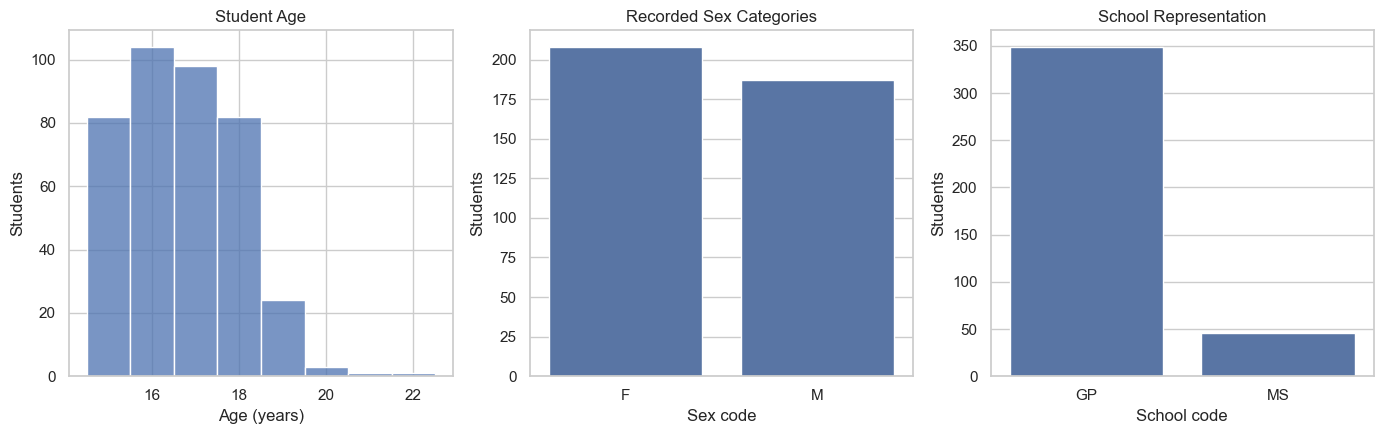

In [9]:
fig, axes = plt.subplots(1, 3, figsize=(14, 4.5))
sns.histplot(data=df, x="age", discrete=True, color=sns.color_palette("deep")[0], ax=axes[0])
axes[0].set(title="Student Age", xlabel="Age (years)", ylabel="Students")
sns.countplot(data=df, x="sex", color=sns.color_palette("deep")[0], ax=axes[1])
axes[1].set(title="Recorded Sex Categories", xlabel="Sex code", ylabel="Students")
sns.countplot(data=df, x="school", color=sns.color_palette("deep")[0], ax=axes[2])
axes[2].set(title="School Representation", xlabel="School code", ylabel="Students")
fig.tight_layout()
fig.savefig(IMAGES_DIR / "demographic_overview.png", dpi=160, bbox_inches="tight")
plt.show()

## 7. Study-time patterns

`studytime` is an ordinal category: 1 represents less than 2 hours per week, 2 represents 2–5 hours, 3 represents 5–10 hours, and 4 represents more than 10 hours. The boxplot compares grade distributions across these groups, rather than assuming a fixed grade increase for every additional hour.

,count,mean,median,std
studytime,,,,
1,105,10.05,10.0,4.96
2,198,10.17,11.0,4.22
3,65,11.40,12.0,4.64
4,27,11.26,12.0,5.28


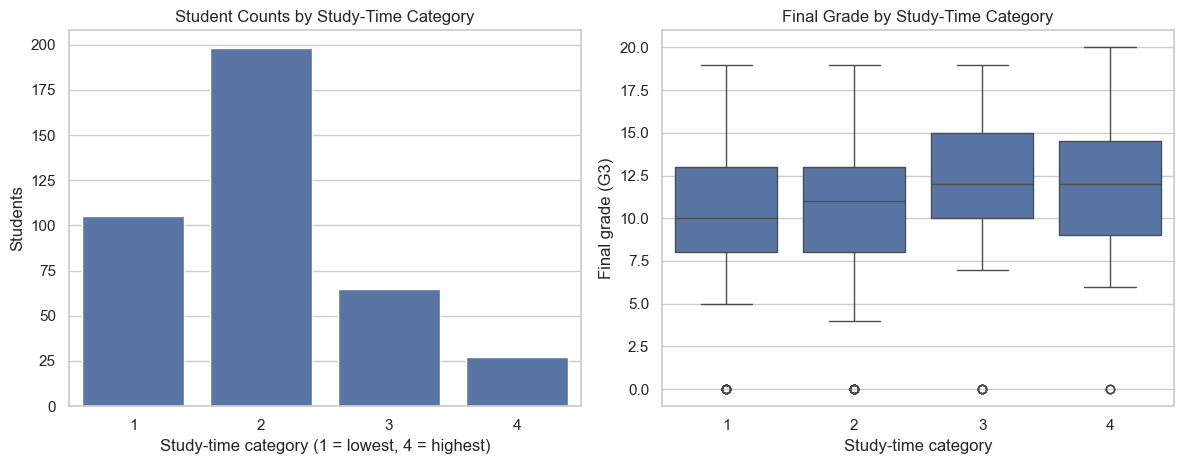

In [10]:
study_summary = df.groupby("studytime", observed=False)["G3"].agg(["count", "mean", "median", "std"]).round(2)
display(study_summary)
fig, axes = plt.subplots(1, 2, figsize=(12, 4.8))
sns.countplot(data=df, x="studytime", color=sns.color_palette("deep")[0], ax=axes[0])
axes[0].set(title="Student Counts by Study-Time Category", xlabel="Study-time category (1 = lowest, 4 = highest)", ylabel="Students")
sns.boxplot(data=df, x="studytime", y="G3", ax=axes[1])
axes[1].set(title="Final Grade by Study-Time Category", xlabel="Study-time category", ylabel="Final grade (G3)")
fig.tight_layout()
fig.savefig(IMAGES_DIR / "studytime_analysis.png", dpi=160, bbox_inches="tight")
plt.show()

## 8. Absences and final grades

Absence counts can be highly skewed. A scatterplot shows individual records and can reveal the variability hidden by averages. High-absence observations are flagged later for review, not automatically deleted: they may be legitimate and useful signals.

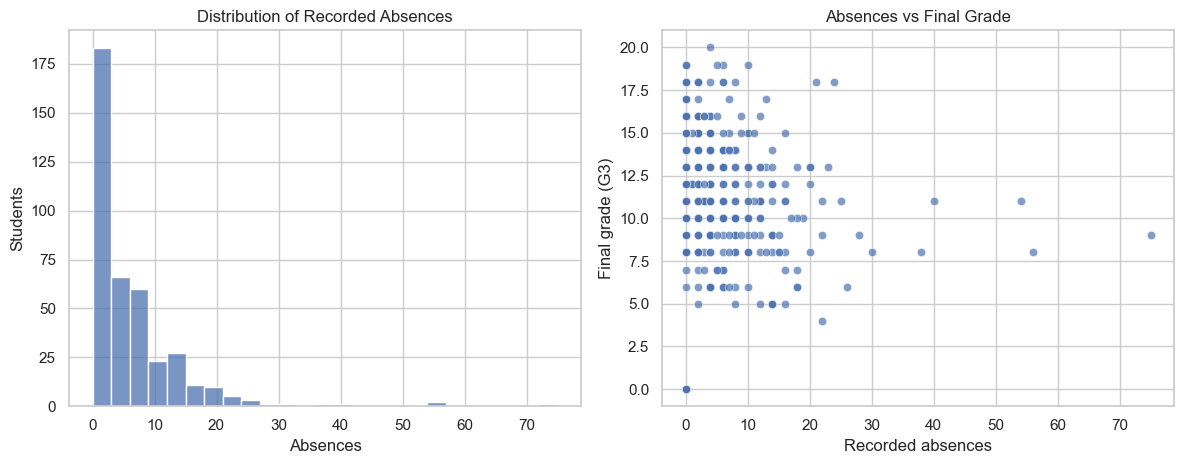

Pearson correlation between absences and G3: 0.034


In [11]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.8))
sns.histplot(data=df, x="absences", bins=25, color=sns.color_palette("deep")[0], ax=axes[0])
axes[0].set(title="Distribution of Recorded Absences", xlabel="Absences", ylabel="Students")
sns.scatterplot(data=df, x="absences", y="G3", alpha=0.7, ax=axes[1])
axes[1].set(title="Absences vs Final Grade", xlabel="Recorded absences", ylabel="Final grade (G3)")
fig.tight_layout()
fig.savefig(IMAGES_DIR / "absences_analysis.png", dpi=160, bbox_inches="tight")
plt.show()
absence_corr = df[["absences", "G3"]].corr().iloc[0, 1]
print(f"Pearson correlation between absences and G3: {absence_corr:.3f}")

## 9. Previous failures and grade patterns

The `failures` feature records previous class failures in this dataset. Its association with `G3` is useful for understanding whether prior difficulty may be a signal for additional support. Because this is observational data, the plot cannot explain why a student struggled.

,count,mean,median
failures,,,
0,312,11.25,11.0
1,50,8.12,9.0
2,17,6.24,8.0
3,16,5.69,7.0


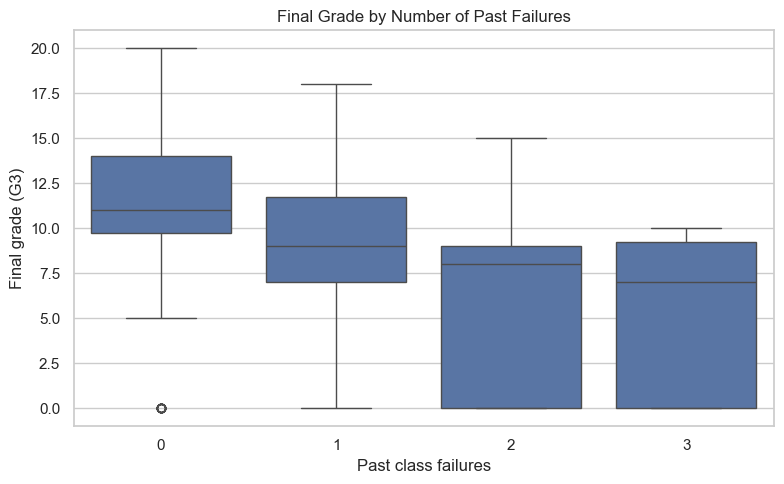

In [12]:
failure_summary = df.groupby("failures", observed=False)["G3"].agg(["count", "mean", "median"]).round(2)
display(failure_summary)
fig, ax = plt.subplots(figsize=(8, 5))
sns.boxplot(data=df, x="failures", y="G3", ax=ax)
ax.set(title="Final Grade by Number of Past Failures", xlabel="Past class failures", ylabel="Final grade (G3)")
fig.tight_layout()
fig.savefig(IMAGES_DIR / "grade_by_failures.png", dpi=160, bbox_inches="tight")
plt.show()

## 10. Family context and final grades

This section examines whether selected family variables have visible associations with grades. These fields can reflect many unmeasured circumstances; they should not be used to blame families or make individual decisions without context.

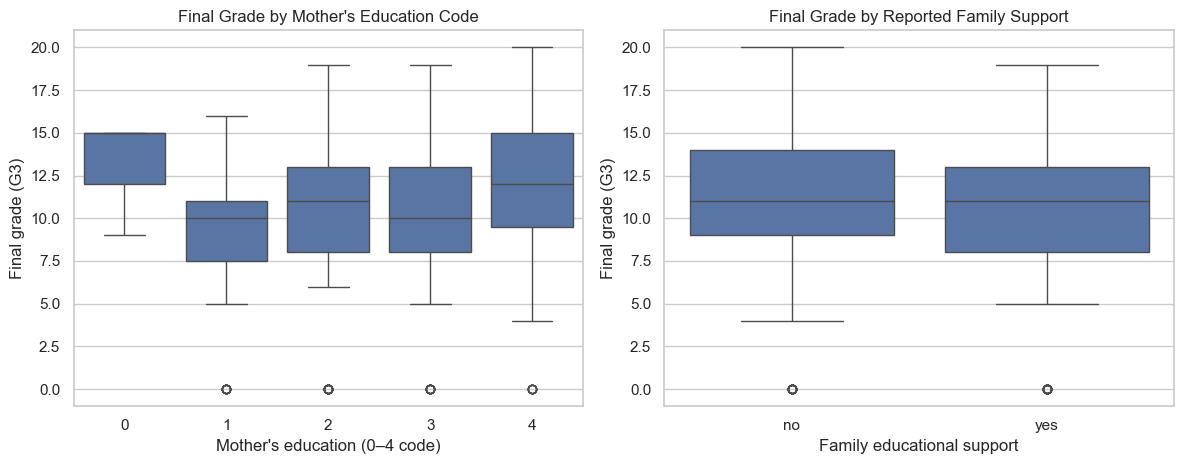

,count,mean,median
famsup,,,
no,153,10.64,11.0
yes,242,10.27,11.0


In [13]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.8))
sns.boxplot(data=df, x="Medu", y="G3", ax=axes[0])
axes[0].set(title="Final Grade by Mother's Education Code", xlabel="Mother's education (0–4 code)", ylabel="Final grade (G3)")
sns.boxplot(data=df, x="famsup", y="G3", ax=axes[1])
axes[1].set(title="Final Grade by Reported Family Support", xlabel="Family educational support", ylabel="Final grade (G3)")
fig.tight_layout()
fig.savefig(IMAGES_DIR / "family_context_analysis.png", dpi=160, bbox_inches="tight")
plt.show()
family_support_summary = df.groupby("famsup", observed=False)["G3"].agg(["count", "mean", "median"]).round(2)
display(family_support_summary)

## 11. Correlation analysis

Correlation is a measure of linear association between numeric fields. A strong correlation can be useful for prediction, but it does not prove causality. The heatmap is an exploratory tool and includes `G1`, `G2`, and `G3`; the later-in-year model intentionally includes previous grades, while the earlier-support model excludes them.

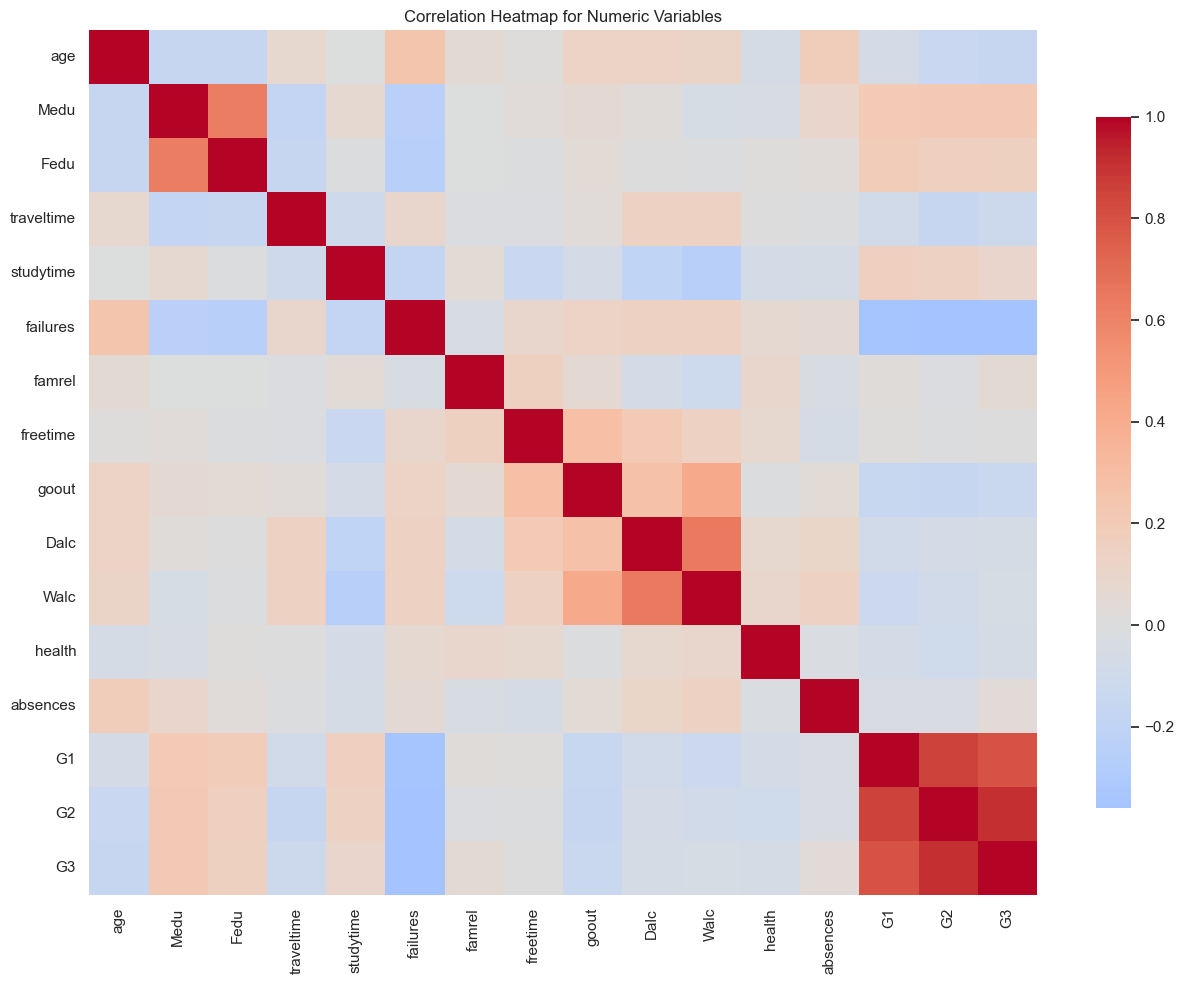

,Correlation with G3
G2,0.905
G1,0.801
failures,-0.360
Medu,0.217
age,-0.162
Fedu,0.152
goout,-0.133
traveltime,-0.117
studytime,0.098
health,-0.061


In [14]:
numeric_df = df.select_dtypes(include=np.number)
correlation = numeric_df.corr()
fig, ax = plt.subplots(figsize=(13, 10))
sns.heatmap(correlation, cmap="coolwarm", center=0, square=False, ax=ax, cbar_kws={"shrink": 0.8})
ax.set(title="Correlation Heatmap for Numeric Variables")
fig.tight_layout()
fig.savefig(IMAGES_DIR / "numeric_correlation_heatmap.png", dpi=160, bbox_inches="tight")
plt.show()

grade_correlations = correlation["G3"].drop("G3").sort_values(key=lambda values: values.abs(), ascending=False)
display(grade_correlations.head(12).to_frame("Correlation with G3").round(3))

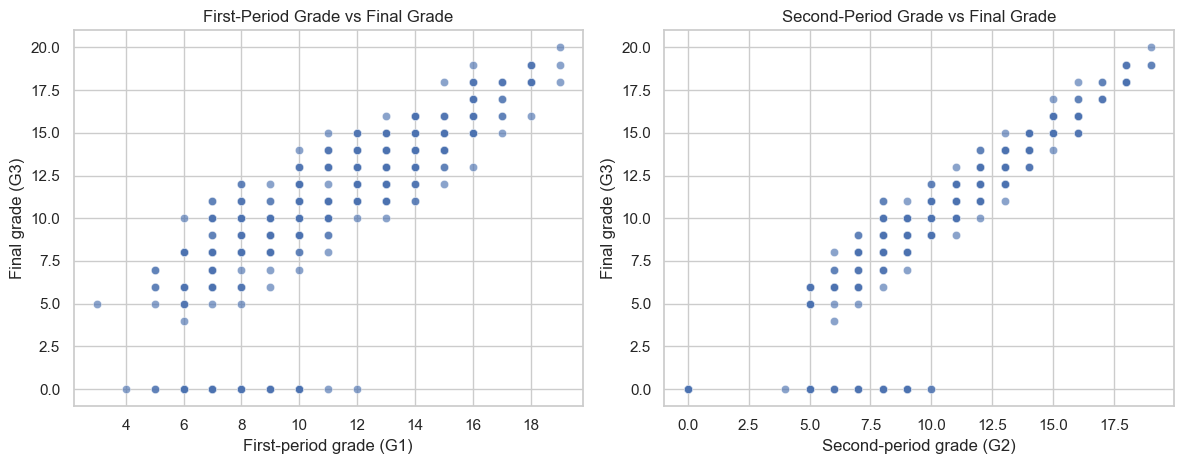

In [15]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.8))
sns.scatterplot(data=df, x="G1", y="G3", alpha=0.65, ax=axes[0])
axes[0].set(title="First-Period Grade vs Final Grade", xlabel="First-period grade (G1)", ylabel="Final grade (G3)")
sns.scatterplot(data=df, x="G2", y="G3", alpha=0.65, ax=axes[1])
axes[1].set(title="Second-Period Grade vs Final Grade", xlabel="Second-period grade (G2)", ylabel="Final grade (G3)")
fig.tight_layout()
fig.savefig(IMAGES_DIR / "prior_grades_vs_final.png", dpi=160, bbox_inches="tight")
plt.show()

## 12. Outlier screening

The interquartile range (IQR) rule is used to flag possible univariate outliers. A flagged record is not automatically an error. For example, a high absence count may be real and relevant, so the project documents unusual values rather than deleting them without evidence.

In [16]:
def iqr_outlier_summary(data: pd.DataFrame, columns: list[str]) -> pd.DataFrame:
    rows = []
    for column in columns:
        series = pd.to_numeric(data[column], errors="coerce").dropna()
        q1, q3 = series.quantile([0.25, 0.75])
        iqr = q3 - q1
        lower, upper = q1 - 1.5 * iqr, q3 + 1.5 * iqr
        rows.append({
            "feature": column, "lower_bound": lower, "upper_bound": upper,
            "flagged_count": int(((series < lower) | (series > upper)).sum()),
            "n_observed": len(series),
        })
    return pd.DataFrame(rows)

outlier_table = iqr_outlier_summary(df, [c for c in ["age", "absences", "G1", "G2", "G3"] if c in df.columns])
display(outlier_table.round(2))

,feature,lower_bound,upper_bound,flagged_count,n_observed
0,age,13.0,21.0,1,395
1,absences,-12.0,20.0,15,395
2,G1,0.5,20.5,0,395
3,G2,3.0,19.0,13,395
4,G3,-1.0,23.0,0,395


## 13. Preliminary EDA findings (computed from the dataset)

The following summaries are generated from the loaded data. They describe associations in this dataset and should not be interpreted as causal claims.

In [17]:
top_correlations = grade_correlations.head(5)
print("Five numeric features with largest absolute correlation with G3:")
display(top_correlations.to_frame("Correlation with G3").round(3))
print(f"\nMean final grade: {df['G3'].mean():.2f} / 20")
print(f"Median final grade: {df['G3'].median():.2f} / 20")
print(f"Number of students with G3 below 10: {(df['G3'] < 10).sum()} ({(df['G3'] < 10).mean():.1%})")
print(f"Absence-G3 correlation: {absence_corr:.3f}")
print("\nStudy-time group means:")
display(study_summary[["count", "mean", "median"]])

Five numeric features with largest absolute correlation with G3:


,Correlation with G3
G2,0.905
G1,0.801
failures,-0.360
Medu,0.217
age,-0.162



Mean final grade: 10.42 / 20
Median final grade: 11.00 / 20
Number of students with G3 below 10: 130 (32.9%)
Absence-G3 correlation: 0.034

Study-time group means:


,count,mean,median
studytime,,,
1,105,10.05,10.0
2,198,10.17,11.0
3,65,11.40,12.0
4,27,11.26,12.0


## 14. Feature engineering

Two engineered predictors are included:

- `parent_education_avg`: average of mother's and father's education codes when available.
- `absence_band`: groups absences into `0`, `1–5`, `6–10`, and `>10` for a simple non-linear representation.

They are derived from predictor columns only, not from the target. The original variables are retained. These engineered features are candidates—not guaranteed improvements—and their usefulness will be reflected in cross-validation and test results.

In [18]:
df_model = df.copy()
parent_columns = [column for column in ["Medu", "Fedu"] if column in df_model.columns]
if parent_columns:
    df_model["parent_education_avg"] = df_model[parent_columns].mean(axis=1)
if "absences" in df_model.columns:
    df_model["absence_band"] = pd.cut(
        df_model["absences"],
        bins=[-1, 0, 5, 10, np.inf],
        labels=["0", "1-5", "6-10", ">10"],
    ).astype("object")

display(df_model[[c for c in ["Medu", "Fedu", "parent_education_avg", "absences", "absence_band", "G3"] if c in df_model]].head())

,Medu,Fedu,parent_education_avg,absences,absence_band,G3
0,4,4,4.0,6,6-10,6
1,1,1,1.0,4,1-5,6
2,1,1,1.0,10,6-10,10
3,4,2,3.0,2,1-5,15
4,3,3,3.0,4,1-5,10


## 15. Modeling plan and prevention of evaluation leakage

- The target is `G3`, a numeric grade, so this is a **supervised regression** problem.
- A random 80/20 train/test split is used with a fixed seed so model comparisons use the same held-out rows.
- Five-fold cross-validation happens only on the training partition.
- `GridSearchCV` tunes Ridge, Lasso, and KNN hyperparameters using training folds.
- Missing-value imputation, scaling, and one-hot encoding are placed in a scikit-learn pipeline, so these preprocessing steps are fitted within each fold.
- The held-out test set is reserved for final comparison. Use RMSE as the primary metric because it is in grade points and penalizes large misses; MAE is a robust-to-large-errors companion metric, and R² gives a familiar measure of explained variation.
- Principal Component Analysis was considered as an exploratory dimensionality-reduction step. It is omitted from the final predictive workflow so the selected model can be interpreted at the original feature level through permutation importance.

The two scenarios are evaluated separately: the early-support scenario excludes `G1`/`G2`, and the later-in-year scenario includes them. The model with the lowest mean cross-validation RMSE is selected for the final diagnostic plots and permutation-importance analysis.

In [19]:
def make_preprocessor(features: pd.DataFrame) -> ColumnTransformer:
    """Fit-safe imputation, scaling, and encoding for mixed feature types."""
    categorical_columns = features.select_dtypes(include=["object", "category", "bool"]).columns.tolist()
    numeric_columns = features.select_dtypes(include=[np.number]).columns.tolist()

    numeric_pipeline = Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler()),
    ])
    categorical_pipeline = Pipeline([
        ("imputer", SimpleImputer(strategy="most_frequent")),
        ("onehot", OneHotEncoder(handle_unknown="ignore")),
    ])
    return ColumnTransformer([
        ("numeric", numeric_pipeline, numeric_columns),
        ("categorical", categorical_pipeline, categorical_columns),
    ], remainder="drop")


def make_model_pipeline(features: pd.DataFrame, estimator) -> Pipeline:
    return Pipeline([
        ("preprocess", make_preprocessor(features)),
        ("regressor", estimator),
    ])


def regression_metrics(actual, predicted) -> dict:
    """Compute metrics in the original grade scale."""
    return {
        "RMSE": float(np.sqrt(mean_squared_error(actual, predicted))),
        "MAE": float(mean_absolute_error(actual, predicted)),
        "R2": float(r2_score(actual, predicted)),
    }

print("Preprocessing, validation, and metric helpers are ready.")

Preprocessing, validation, and metric helpers are ready.


## 16. Candidate models and hyperparameter search

The mean-only regressor is a reference point: a useful model should improve on simply predicting the training-set mean. Linear Regression is the baseline requested by the capstone proposal. Ridge and Lasso add regularization, while KNN regression provides a non-parametric comparison.

Hyperparameter values are deliberately kept to a manageable grid so the analysis remains reproducible for a small course dataset.

In [20]:
model_specs = {
    "Mean baseline": (DummyRegressor(strategy="mean"), None),
    "Linear Regression": (LinearRegression(), None),
    "Ridge Regression": (Ridge(), {"regressor__alpha": [0.01, 0.1, 1, 10, 100, 500]}),
    "Lasso Regression": (Lasso(max_iter=30000), {"regressor__alpha": [0.001, 0.01, 0.1, 0.5, 1.0]}),
    "KNN Regression": (KNeighborsRegressor(), {
        "regressor__n_neighbors": [3, 5, 7, 9, 13, 17, 21],
        "regressor__weights": ["uniform", "distance"],
        "regressor__p": [1, 2],
    }),
}
cv = KFold(n_splits=N_SPLITS, shuffle=True, random_state=RANDOM_STATE)
print("Candidate models:", ", ".join(model_specs))
print(f"Cross-validation folds: {N_SPLITS}; held-out test fraction: {TEST_SIZE:.0%}")

Candidate models: Mean baseline, Linear Regression, Ridge Regression, Lasso Regression, KNN Regression
Cross-validation folds: 5; held-out test fraction: 20%


## 17. Train, cross-validate, tune, and evaluate models

For each scenario, model pipelines share the same train/test split. The mean baseline and Linear Regression are evaluated with five-fold cross-validation. Ridge, Lasso, and KNN use `GridSearchCV` to select hyperparameters by mean cross-validation RMSE. Each selected estimator is then evaluated on the held-out test partition.

In [21]:
y = df_model["G3"].astype(float)
all_features = df_model.drop(columns=["G3"])
early_features = all_features.drop(columns=[column for column in ["G1", "G2"] if column in all_features.columns])
scenarios = {
    "Earlier support (no G1/G2)": early_features,
    "Later in year (with G1/G2)": all_features,
}

results_rows = []
fitted_models = {}
scenario_splits = {}

for scenario_name, X in scenarios.items():
    print(f"\nScenario: {scenario_name} | features: {X.shape[1]}")
    X_train, X_test, y_train, y_test = train_test_split(
        X, y, test_size=TEST_SIZE, random_state=RANDOM_STATE
    )
    scenario_splits[scenario_name] = (X_train, X_test, y_train, y_test)

    for model_name, (estimator, parameter_grid) in model_specs.items():
        pipeline = make_model_pipeline(X_train, estimator)
        if parameter_grid:
            search = GridSearchCV(
                estimator=pipeline,
                param_grid=parameter_grid,
                cv=cv,
                scoring="neg_root_mean_squared_error",
                n_jobs=-1,
                refit=True,
                error_score="raise",
            )
            search.fit(X_train, y_train)
            best_model = search.best_estimator_
            cv_rmse_mean = float(-search.best_score_)
            cv_rmse_sd = float(search.cv_results_["std_test_score"][search.best_index_])
            best_params = str(search.best_params_)
        else:
            cv_scores = cross_validate(
                pipeline, X_train, y_train, cv=cv,
                scoring="neg_root_mean_squared_error", n_jobs=-1,
            )
            fold_rmse = -cv_scores["test_score"]
            cv_rmse_mean = float(fold_rmse.mean())
            cv_rmse_sd = float(fold_rmse.std(ddof=1))
            best_model = pipeline.fit(X_train, y_train)
            best_params = "{}"

        predictions = best_model.predict(X_test)
        metrics = regression_metrics(y_test, predictions)
        results_rows.append({
            "Scenario": scenario_name,
            "Model": model_name,
            "CV_RMSE_Mean": cv_rmse_mean,
            "CV_RMSE_SD": cv_rmse_sd,
            "Test_RMSE": metrics["RMSE"],
            "Test_MAE": metrics["MAE"],
            "Test_R2": metrics["R2"],
            "Best_Params": best_params,
        })
        fitted_models[(scenario_name, model_name)] = best_model
        print(f"  {model_name}: CV RMSE={cv_rmse_mean:.3f}; Test RMSE={metrics['RMSE']:.3f}")

results_df = pd.DataFrame(results_rows).sort_values("CV_RMSE_Mean").reset_index(drop=True)
display(results_df[["Scenario", "Model", "CV_RMSE_Mean", "CV_RMSE_SD", "Test_RMSE", "Test_MAE", "Test_R2", "Best_Params"]].round(3))


Scenario: Earlier support (no G1/G2) | features: 32


  Mean baseline: CV RMSE=4.563; Test RMSE=4.550


  Linear Regression: CV RMSE=4.341; Test RMSE=4.098


  Ridge Regression: CV RMSE=4.135; Test RMSE=4.046
  Lasso Regression: CV RMSE=4.092; Test RMSE=4.123


  KNN Regression: CV RMSE=4.230; Test RMSE=4.050

Scenario: Later in year (with G1/G2) | features: 34
  Mean baseline: CV RMSE=4.563; Test RMSE=4.550
  Linear Regression: CV RMSE=1.887; Test RMSE=2.212


  Ridge Regression: CV RMSE=1.833; Test RMSE=2.174
  Lasso Regression: CV RMSE=1.731; Test RMSE=1.947


  KNN Regression: CV RMSE=2.636; Test RMSE=2.968


,Scenario,Model,CV_RMSE_Mean,CV_RMSE_SD,Test_RMSE,Test_MAE,Test_R2,Best_Params
0,Later in year (with G1/G2),Lasso Regression,1.731,0.372,1.947,1.278,0.815,{'regressor__alpha': 0.1}
1,Later in year (with G1/G2),Ridge Regression,1.833,0.286,2.174,1.602,0.769,{'regressor__alpha': 10}
2,Later in year (with G1/G2),Linear Regression,1.887,0.322,2.212,1.652,0.761,{}
3,Later in year (with G1/G2),KNN Regression,2.636,0.512,2.968,2.170,0.571,"{'regressor__n_neighbors': 5, 'regressor__p': ..."
4,Earlier support (no G1/G2),Lasso Regression,4.092,0.406,4.123,3.374,0.171,{'regressor__alpha': 0.1}
5,Earlier support (no G1/G2),Ridge Regression,4.135,0.425,4.046,3.273,0.202,{'regressor__alpha': 100}
6,Earlier support (no G1/G2),KNN Regression,4.230,0.443,4.050,3.253,0.200,"{'regressor__n_neighbors': 21, 'regressor__p':..."
7,Earlier support (no G1/G2),Linear Regression,4.341,0.366,4.098,3.315,0.181,{}
8,Earlier support (no G1/G2),Mean baseline,4.563,0.709,4.550,3.646,-0.010,{}
9,Later in year (with G1/G2),Mean baseline,4.563,0.709,4.550,3.646,-0.010,{}


## 18. Model comparison and metric interpretation

- **RMSE:** typical scale of error, with extra penalty for large mistakes; lower is better.
- **MAE:** average absolute error in grade points; lower is better.
- **R²:** proportion of test-set grade variation explained relative to predicting a constant mean; higher is generally better, and it can be negative if the model performs poorly.
- **Cross-validation RMSE:** average validation performance across training folds. It is used for model selection.
- **Test RMSE/MAE/R²:** measured on the held-out test set after model selection; this is the best estimate available here of generalization to unseen records from this dataset.

A smaller RMSE alone does not establish that a model is fair, causal, or suitable for operational decisions.

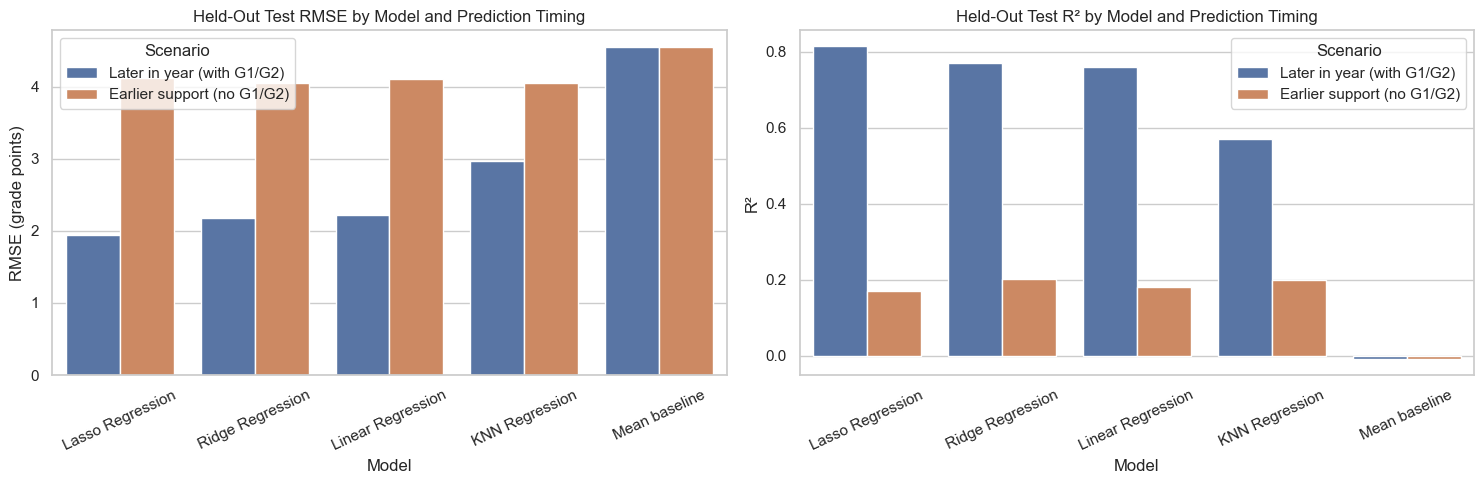

,Scenario,Model,CV_RMSE_Mean,Test_RMSE,Test_MAE,Test_R2,Best_Params
4,Earlier support (no G1/G2),Lasso Regression,4.092,4.123,3.374,0.171,{'regressor__alpha': 0.1}
0,Later in year (with G1/G2),Lasso Regression,1.731,1.947,1.278,0.815,{'regressor__alpha': 0.1}


In [22]:
# Save the comparison table for auditability and the final README/report.
REPORTS_DIR.mkdir(parents=True, exist_ok=True)
results_df.to_csv(REPORTS_DIR / "model_comparison.csv", index=False)

plot_results = results_df.copy()
fig, axes = plt.subplots(1, 2, figsize=(15, 5))
sns.barplot(data=plot_results, x="Model", y="Test_RMSE", hue="Scenario", ax=axes[0])
axes[0].set(title="Held-Out Test RMSE by Model and Prediction Timing", xlabel="Model", ylabel="RMSE (grade points)")
axes[0].tick_params(axis="x", rotation=25)
sns.barplot(data=plot_results, x="Model", y="Test_R2", hue="Scenario", ax=axes[1])
axes[1].set(title="Held-Out Test R² by Model and Prediction Timing", xlabel="Model", ylabel="R²")
axes[1].tick_params(axis="x", rotation=25)
fig.tight_layout()
fig.savefig(IMAGES_DIR / "model_comparison.png", dpi=160, bbox_inches="tight")
plt.show()

best_by_scenario = results_df.loc[results_df.groupby("Scenario")["CV_RMSE_Mean"].idxmin()].sort_values("Scenario")
display(best_by_scenario[["Scenario", "Model", "CV_RMSE_Mean", "Test_RMSE", "Test_MAE", "Test_R2", "Best_Params"]].round(3))

## 19. Select a model using cross-validation

The candidate with the lowest mean five-fold cross-validation RMSE is selected for diagnostic plots and feature-importance analysis. Test metrics are reported for transparency, but the selection rule is based on training cross-validation rather than picking whichever model happened to have the smallest test error.

In [23]:
best_row = results_df.loc[results_df["CV_RMSE_Mean"].idxmin()]
best_scenario = best_row["Scenario"]
best_model_name = best_row["Model"]
best_model = fitted_models[(best_scenario, best_model_name)]
X_train, X_test, y_train, y_test = scenario_splits[best_scenario]
y_pred = best_model.predict(X_test)

print(f"Selected using CV RMSE: {best_model_name}")
print(f"Prediction setting: {best_scenario}")
print(f"CV RMSE: {best_row['CV_RMSE_Mean']:.3f} ± {best_row['CV_RMSE_SD']:.3f} grade points")
print(f"Held-out RMSE: {best_row['Test_RMSE']:.3f} grade points")
print(f"Held-out MAE: {best_row['Test_MAE']:.3f} grade points")
print(f"Held-out R²: {best_row['Test_R2']:.3f}")

scenario_winners = results_df.loc[results_df.groupby("Scenario")["CV_RMSE_Mean"].idxmin()].set_index("Scenario")
early_cv = scenario_winners.loc["Earlier support (no G1/G2)", "CV_RMSE_Mean"]
late_cv = scenario_winners.loc["Later in year (with G1/G2)", "CV_RMSE_Mean"]
if late_cv < early_cv:
    improvement = (early_cv - late_cv) / early_cv * 100
    print(f"Including G1/G2 reduced best CV RMSE by {improvement:.1f}% compared with the earlier-support setting.")
else:
    difference = (late_cv - early_cv) / early_cv * 100
    print(f"The later-in-year setting did not improve best CV RMSE in this run ({difference:.1f}% higher than earlier-support CV RMSE).")

Selected using CV RMSE: Lasso Regression
Prediction setting: Later in year (with G1/G2)
CV RMSE: 1.731 ± 0.372 grade points
Held-out RMSE: 1.947 grade points
Held-out MAE: 1.278 grade points
Held-out R²: 0.815
Including G1/G2 reduced best CV RMSE by 57.7% compared with the earlier-support setting.


## 20. Prediction diagnostics

Actual-versus-predicted points near the diagonal indicate more accurate estimates. Residuals are actual minus predicted grades. A pattern in residuals can indicate systematic underprediction/overprediction or errors that vary across the grade range. These plots complement—not replace—the numerical metrics.

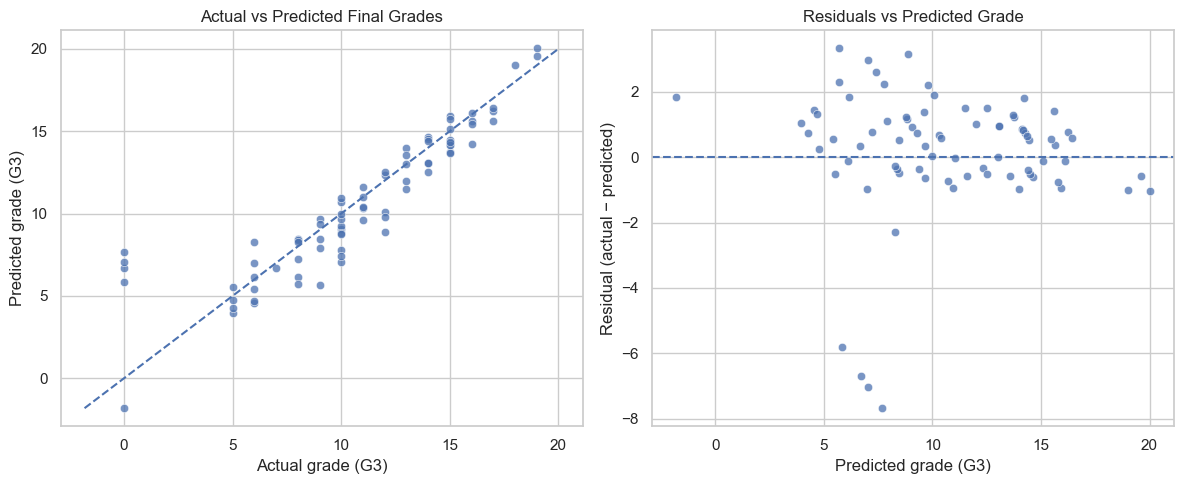

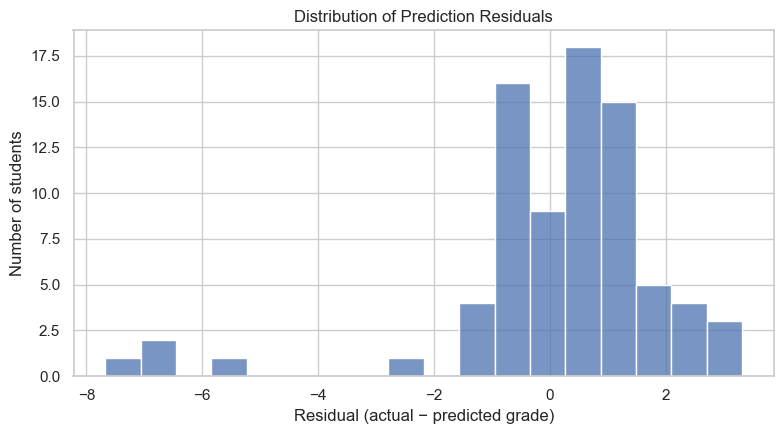

In [24]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5))
sns.scatterplot(x=y_test, y=y_pred, alpha=0.75, ax=axes[0])
axis_min = min(float(y_test.min()), float(np.min(y_pred)))
axis_max = max(float(y_test.max()), float(np.max(y_pred)))
axes[0].plot([axis_min, axis_max], [axis_min, axis_max], linestyle="--")
axes[0].set(title="Actual vs Predicted Final Grades", xlabel="Actual grade (G3)", ylabel="Predicted grade (G3)")
residuals = y_test.to_numpy() - y_pred
sns.scatterplot(x=y_pred, y=residuals, alpha=0.75, ax=axes[1])
axes[1].axhline(0, linestyle="--")
axes[1].set(title="Residuals vs Predicted Grade", xlabel="Predicted grade (G3)", ylabel="Residual (actual − predicted)")
fig.tight_layout()
fig.savefig(IMAGES_DIR / "prediction_diagnostics.png", dpi=160, bbox_inches="tight")
plt.show()

fig, ax = plt.subplots(figsize=(8, 4.5))
sns.histplot(residuals, bins=18, color=sns.color_palette("deep")[0], ax=ax)
ax.set(title="Distribution of Prediction Residuals", xlabel="Residual (actual − predicted grade)", ylabel="Number of students")
fig.tight_layout()
fig.savefig(IMAGES_DIR / "residual_distribution.png", dpi=160, bbox_inches="tight")
plt.show()

## 21. Permutation importance

Permutation importance measures how much the chosen model's evaluation score worsens when one input column is shuffled. A larger increase in RMSE indicates that the model relied more on that feature for this test set. This is a predictive diagnostic—not a causal effect—and correlated features can share or dilute apparent importance.

,feature,importance_mean,importance_sd
31,G2,3.1085,0.2134
33,absence_band,0.1977,0.0482
30,G1,0.1666,0.0482
23,famrel,0.0596,0.0280
2,age,0.0110,0.0149
28,health,0.0003,0.0003
1,sex,0.0000,0.0000
32,parent_education_avg,0.0000,0.0000
27,Walc,0.0000,0.0000
26,Dalc,0.0000,0.0000


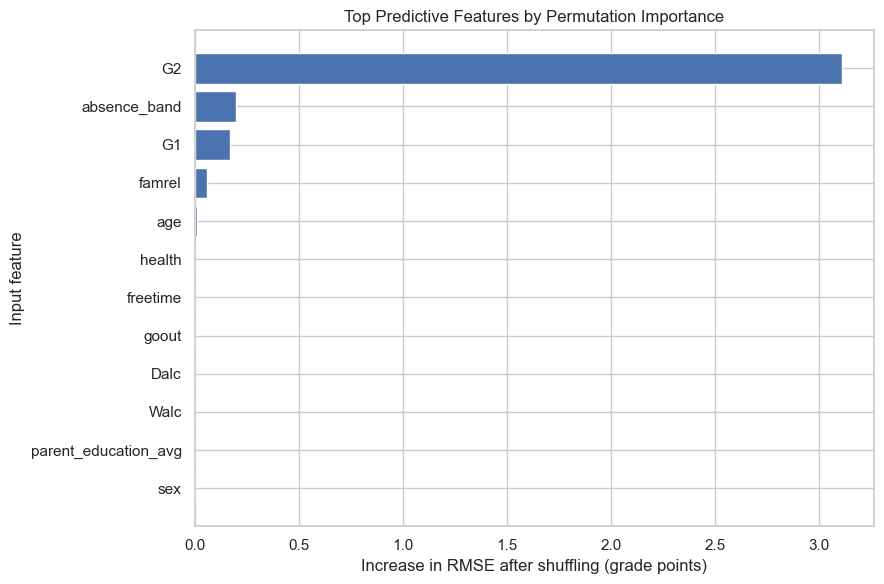

In [25]:
permutation = permutation_importance(
    best_model,
    X_test,
    y_test,
    n_repeats=10,
    random_state=RANDOM_STATE,
    scoring="neg_root_mean_squared_error",
    n_jobs=-1,
)
importance_df = pd.DataFrame({
    "feature": X_test.columns,
    "importance_mean": permutation.importances_mean,
    "importance_sd": permutation.importances_std,
}).sort_values("importance_mean", ascending=False)
display(importance_df.head(15).round(4))
importance_df.to_csv(REPORTS_DIR / "permutation_importance.csv", index=False)

plot_importance = importance_df.head(12).sort_values("importance_mean", ascending=True)
fig, ax = plt.subplots(figsize=(9, 6))
ax.barh(plot_importance["feature"], plot_importance["importance_mean"])
ax.set(title="Top Predictive Features by Permutation Importance", xlabel="Increase in RMSE after shuffling (grade points)", ylabel="Input feature")
fig.tight_layout()
fig.savefig(IMAGES_DIR / "permutation_importance.png", dpi=160, bbox_inches="tight")
plt.show()

## 22. What the results mean for educators

The next cell generates a concise, evidence-based summary. It uses measured outputs from this run and avoids causal language. A high-importance variable means the fitted model used that variable to predict grades in this dataset; it does not mean that changing the variable will necessarily change a student's result.

In [26]:
# Summarize the top features with careful, non-causal wording.
top_features = importance_df.head(5)
print(f"The model selected by training CV was {best_model_name} in the '{best_scenario}' scenario.")
print(f"On held-out records, its predictions had RMSE {best_row['Test_RMSE']:.2f} and MAE {best_row['Test_MAE']:.2f} grade points (R² {best_row['Test_R2']:.2f}).")
print("\nMost useful predictive signals in this run (permutation importance):")
for row in top_features.itertuples(index=False):
    print(f"- {row.feature}: mean RMSE increase {row.importance_mean:.3f} grade points when shuffled")
print("\nThese findings should be used to prompt supportive conversations and further local validation—not to label, penalize, or deny services to students.")

The model selected by training CV was Lasso Regression in the 'Later in year (with G1/G2)' scenario.
On held-out records, its predictions had RMSE 1.95 and MAE 1.28 grade points (R² 0.82).

Most useful predictive signals in this run (permutation importance):
- G2: mean RMSE increase 3.109 grade points when shuffled
- absence_band: mean RMSE increase 0.198 grade points when shuffled
- G1: mean RMSE increase 0.167 grade points when shuffled
- famrel: mean RMSE increase 0.060 grade points when shuffled
- age: mean RMSE increase 0.011 grade points when shuffled

These findings should be used to prompt supportive conversations and further local validation—not to label, penalize, or deny services to students.


## 23. Actionable recommendations

Use the measured findings and the prediction-timing scenario to guide recommendations:

1. **Support-focused review:** If prior grades are among the most useful signals, educators can review them alongside teacher observations and student context to offer tutoring or a check-in. This is suitable later in the year, not before those grades exist.
2. **Earlier monitoring:** For the early-support scenario, examine which behavior/context variables contribute predictive signal. Treat those variables as prompts for follow-up, not as fixed judgments about a student.
3. **Human review and privacy:** A prediction should never independently determine access to tutoring, course placement, discipline, or other high-impact outcomes. Protect student-level data and communicate uncertainty.
4. **Local validation before implementation:** Re-train and evaluate on recent data from the intended school, check error rates across groups, and consult teachers, students, families, and privacy leads.
5. **Measure impact:** If a school later pilots a support process, evaluate whether it improves student outcomes—not only whether a model predicts grades accurately.

## 24. Limitations and next steps

- **Population/context:** The observations come from two Portuguese secondary schools and may not represent other settings or current learners.
- **Data size:** The mathematics file is relatively small, so test metrics may vary with a different split.
- **Predictive versus causal:** Associations do not show that changing study time, family support, or absences will directly change final grades.
- **Timing:** The model including `G1` and `G2` is not an early-semester model. The early-support scenario is the more actionable one for earlier intervention, even if its predictive accuracy is lower.
- **Fairness:** Group-level errors and the implications of using demographic variables should be assessed before any real-world use.
- **PCA:** Principal Component Analysis was considered but omitted from the final predictive workflow. Reducing the original variables to components would make it harder to explain which student, family, and school variables are associated with the grade prediction.
- **Next steps:** Validate on recent local data, report uncertainty, evaluate subgroup performance, compare with additional algorithms only when justified, and review the intervention process with educators.

## 25. Save deliverables and update the README results section

This cell saves the metric table, writes a human-readable results summary, saves the key charts under `images/`, and replaces the marked Results block in the project README. It means the README can report **measured** results after the notebook has actually been run.

In [27]:
# Produce a concise Markdown summary for the README and reports folder.
summary_columns = ["Scenario", "Model", "CV_RMSE_Mean", "Test_RMSE", "Test_MAE", "Test_R2"]
leaderboard = results_df[summary_columns].head(8).round(3)
markdown_table = leaderboard.to_markdown(index=False)
feature_bullets = "\n".join(
    f"- `{row.feature}` (RMSE increase after permutation: {row.importance_mean:.3f} grade points)"
    for row in top_features.itertuples(index=False)
)
results_markdown = f"""**Best model by 5-fold cross-validation RMSE:** {best_model_name} — {best_scenario}.  
Held-out test results: RMSE **{best_row['Test_RMSE']:.3f}**, MAE **{best_row['Test_MAE']:.3f}**, R² **{best_row['Test_R2']:.3f}**.

RMSE and MAE are in grade points (lower is better); R² measures how much variation in held-out grades is explained. The model was selected using cross-validation on training data, then evaluated on the held-out test set.

**Top predictive signals in the selected model** (associations, not causal effects):

{feature_bullets}

**Leading model comparisons:**

{markdown_table}

**Interpretation:** Use the earlier-support scenario for decisions that must be made before prior-period grades are available. The later-in-year scenario uses G1/G2 and should not be represented as an early-warning model. Validate on recent local data, assess group-level errors, and keep humans responsible for student-support decisions.

**Data attribution:** Cortez, P. (2008). *Student Performance* [Dataset]. UCI Machine Learning Repository. https://doi.org/10.24432/C5TG7T. This analysis uses the mathematics file included at `data/student-mat.csv` (CC BY 4.0).
"""
(REPORTS_DIR / "results_summary.md").write_text(results_markdown, encoding="utf-8")
results_df.to_csv(REPORTS_DIR / "model_comparison.csv", index=False)

readme_path = PROJECT_ROOT / "README.md"
if readme_path.exists():
    readme_text = readme_path.read_text(encoding="utf-8")
    start_marker = "<!-- AUTO_RESULTS_START -->"
    end_marker = "<!-- AUTO_RESULTS_END -->"
    if start_marker in readme_text and end_marker in readme_text:
        prefix, after_start = readme_text.split(start_marker, 1)
        _, suffix = after_start.split(end_marker, 1)
        readme_text = prefix + start_marker + "\n" + results_markdown + "\n" + end_marker + suffix
        readme_path.write_text(readme_text, encoding="utf-8")
        print(f"Updated README results section: {readme_path}")
    else:
        print("README auto-results markers were not found; results_summary.md was still saved.")
else:
    print("README.md not found from this notebook's working directory; results_summary.md was still saved.")

print(f"Saved model comparison: {REPORTS_DIR / 'model_comparison.csv'}")
print(f"Saved permutation importance: {REPORTS_DIR / 'permutation_importance.csv'}")
print(f"Saved results summary: {REPORTS_DIR / 'results_summary.md'}")
print(f"Saved charts to: {IMAGES_DIR}")
display(leaderboard)

Updated README results section: /Users/sunitpoddar/Downloads/Student-Performance-Prediction-Capstone/README.md
Saved model comparison: /Users/sunitpoddar/Downloads/Student-Performance-Prediction-Capstone/reports/model_comparison.csv
Saved permutation importance: /Users/sunitpoddar/Downloads/Student-Performance-Prediction-Capstone/reports/permutation_importance.csv
Saved results summary: /Users/sunitpoddar/Downloads/Student-Performance-Prediction-Capstone/reports/results_summary.md
Saved charts to: /Users/sunitpoddar/Downloads/Student-Performance-Prediction-Capstone/images


,Scenario,Model,CV_RMSE_Mean,Test_RMSE,Test_MAE,Test_R2
0,Later in year (with G1/G2),Lasso Regression,1.731,1.947,1.278,0.815
1,Later in year (with G1/G2),Ridge Regression,1.833,2.174,1.602,0.769
2,Later in year (with G1/G2),Linear Regression,1.887,2.212,1.652,0.761
3,Later in year (with G1/G2),KNN Regression,2.636,2.968,2.170,0.571
4,Earlier support (no G1/G2),Lasso Regression,4.092,4.123,3.374,0.171
5,Earlier support (no G1/G2),Ridge Regression,4.135,4.046,3.273,0.202
6,Earlier support (no G1/G2),KNN Regression,4.230,4.050,3.253,0.200
7,Earlier support (no G1/G2),Linear Regression,4.341,4.098,3.315,0.181


## 26. Conclusion

This project evaluates whether available student information can help estimate final mathematics grades and compares the trade-off between earlier prediction and the additional predictive signal in prior-period grades. The final interpretation should be based on the computed model table, selected-model metrics, and feature-importance output above.

The main practical goal is not to automate decisions about students. It is to identify potentially useful signals, make uncertainty visible, and give educators a transparent starting point for supportive, human-led intervention. Before any operational use, the model must be validated on current local data and reviewed for fairness, privacy, and unintended consequences.